# Entrenamiento y selección de modelos

Torneo de modelos para predecir `SalePrice` con las features de `MODEL_FEATURES`. Cada modelo se optimiza con `GridSearchCV` y validación cruzada de 10 folds, y se compara contra el split de validación.

| Elemento | Definición |
|---|---|
| Modelos | Regresión lineal (base), Ridge, Lasso, Random Forest, Gradient Boosting, MLP |
| Optimización | `GridSearchCV`, `KFold` de 10 folds, al menos 3 configuraciones por modelo |
| Métrica de optimización | RMSE en escala real (`expm1` de las predicciones en log) |
| Métricas del torneo | RMSE real y RMSE normalizado al rango de `SalePrice` en entrenamiento (NRMSE) |
| Control de sobreajuste | Brecha entre el RMSE de entrenamiento y el de validación cruzada |

**Prevención de fuga de datos:** el preprocesamiento del notebook `2.0` forma parte del pipeline de cada modelo y se reajusta dentro de cada fold. Por eso se parte de los datos crudos y no de `data/processed/`, cuyos transformadores fueron ajustados con todo el split de entrenamiento. El split de validación no interviene en el ajuste ni en la selección de hiperparámetros.

## 1. Librerías

Carga de librerías de manipulación de datos, visualización, transformadores de `feature-engine` y utilidades de modelado de scikit-learn.

In [14]:
# Librerías
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import make_scorer, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from feature_engine.encoding import OrdinalEncoder
from feature_engine.imputation import CategoricalImputer, MeanMedianImputer
from feature_engine.outliers import Winsorizer
from feature_engine.wrappers import SklearnTransformerWrapper

from house_pricing_a.config import MODELS_DIR, PROJ_ROOT, RAW_DATA_DIR
from house_pricing_a.features import SkewedYeoJohnsonTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Carga de datos y configuración

Lectura de `train.csv` crudo y de la lista de features en `pipeline_config.yaml`. `test.csv` no se utiliza en este notebook porque no contiene el target.

In [2]:
# Rutas y parámetros: ajustar si cambia la fuente
DATA_DIR = RAW_DATA_DIR
TRAIN_FILE = "train.csv"
PIPELINE_CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"

TARGET = "SalePrice"
ID_COL = "Id"

with open(PIPELINE_CONFIG_PATH) as f:
    pipeline_config = yaml.safe_load(f)
MODEL_FEATURES = pipeline_config["MODEL_FEATURES"]

train = pd.read_csv(DATA_DIR / TRAIN_FILE, index_col=ID_COL)
print(f"train: {train.shape} | features: {len(MODEL_FEATURES)}")

train: (1460, 80) | features: 30


## 3. División train/validación

Mismo split del notebook `2.0` (80/20, `random_state=42`), por lo que las filas de validación coinciden con `data/processed/validation.csv`. El modelo se entrena con `SalePrice_log` (`log1p`) y las métricas se calculan en escala real con `expm1`.

In [3]:
# Split train/validación (idéntico al notebook 2.0)
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_val, y_train, y_val = train_test_split(
    train[MODEL_FEATURES],
    np.log1p(train[TARGET]),
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

# Rango del target real en entrenamiento: denominador del NRMSE
y_train_real = np.expm1(y_train)
RANGO_TRAIN = y_train_real.max() - y_train_real.min()

print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")
print(f"Rango de SalePrice en entrenamiento: {RANGO_TRAIN:,.0f}")

X_train: (1168, 30) | X_val: (292, 30)
Rango de SalePrice en entrenamiento: 710,100


## 4. Pipeline de preprocesamiento

Reconstrucción del preprocesamiento del notebook `2.0` con los mismos pasos y parámetros. Dos ajustes evitan fuga de datos dentro de la validación cruzada:

- La clasificación en continuas, discretas y categóricas se calcula solo con `X_train`.
- La selección de variables sesgadas para Yeo-Johnson se realiza dentro del `fit` (`SkewedYeoJohnsonTransformer`, definido en `house_pricing_a/features.py` para que el modelo guardado pueda cargarse desde otros notebooks), de modo que en cada fold el sesgo se mide únicamente con los datos de entrenamiento del fold. En el notebook `2.0` la lista era fija porque el pipeline se ajustaba una sola vez.

In [4]:
# Clasificación de features con X_train
MAX_UNIQUE_DISCRETE = 15
SKEW_THRESHOLD = 0.75

numericas = X_train.select_dtypes(include="number").columns.tolist()
categoricas = X_train.select_dtypes(exclude="number").columns.tolist()
n_unique = X_train[numericas].nunique()
continuas = [col for col in numericas if n_unique[col] > MAX_UNIQUE_DISCRETE]


def build_preprocessing():
    return [
        ("imputacion_numericas", MeanMedianImputer(imputation_method="median", variables=numericas)),
        ("imputacion_categoricas", CategoricalImputer(imputation_method="frequent", variables=categoricas)),
        ("codificacion", OrdinalEncoder(encoding_method="ordered", variables=categoricas, unseen="encode")),
        ("outliers", Winsorizer(capping_method="iqr", tail="both", fold=1.5, variables=continuas)),
        ("transformacion", SkewedYeoJohnsonTransformer(variables=continuas, threshold=SKEW_THRESHOLD)),
        ("escalado", SklearnTransformerWrapper(transformer=StandardScaler(), variables=MODEL_FEATURES)),
    ]

## 5. Métricas

- **RMSE real:** error cuadrático medio, en dólares, tras revertir el target y las predicciones con `expm1`. Es la métrica que optimiza `GridSearchCV`.
- **NRMSE:** RMSE real dividido entre el rango de `SalePrice` en entrenamiento (`RANGO_TRAIN`). Expresa el error como proporción del rango de precios.

In [5]:
# RMSE en escala real y NRMSE
def rmse_real(y_true_log, y_pred_log):
    return root_mean_squared_error(np.expm1(y_true_log), np.expm1(y_pred_log))


def nrmse(y_true_log, y_pred_log, rango=RANGO_TRAIN):
    return rmse_real(y_true_log, y_pred_log) / rango


rmse_real_scorer = make_scorer(rmse_real, greater_is_better=False)

## 6. Modelos y grillas de hiperparámetros

Definición de los modelos del torneo y de sus grillas. Las grillas incluyen parámetros que controlan la complejidad (regularización, profundidad, tamaño mínimo de hoja, `early_stopping`). La regresión lineal es el modelo base y no tiene hiperparámetros que optimizar.

In [6]:
# Modelos y grillas (prefijo "modelo__" por estar dentro del Pipeline)
modelos = {
    "Regresión lineal": (LinearRegression(), {}),
    "Ridge": (
        Ridge(),
        {"modelo__alpha": [0.1, 1, 10, 30, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=10_000),
        {"modelo__alpha": [0.0005, 0.001, 0.005, 0.01, 0.05]},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "modelo__max_depth": [None, 10, 20],
            "modelo__min_samples_leaf": [1, 3, 5],
            "modelo__max_features": [0.33, "sqrt"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(subsample=0.8, random_state=RANDOM_STATE),
        {
            "modelo__n_estimators": [300, 600],
            "modelo__learning_rate": [0.03, 0.1],
            "modelo__max_depth": [2, 3, 4],
        },
    ),
    "MLP": (
        MLPRegressor(early_stopping=True, max_iter=2000, random_state=RANDOM_STATE),
        {
            "modelo__hidden_layer_sizes": [(64,), (64, 32), (128, 64)],
            "modelo__alpha": [0.001, 0.01, 0.1],
        },
    ),
}

pd.DataFrame({
    "configuraciones": {name: int(np.prod([len(v) for v in grid.values()])) for name, (_, grid) in modelos.items()}
})

,configuraciones
Regresión lineal,1
Ridge,5
Lasso,5
Random Forest,18
Gradient Boosting,12
MLP,9


## 7. Validación cruzada y optimización de hiperparámetros

Para cada modelo se construye `Pipeline(preprocesamiento + modelo)` y se optimiza con `GridSearchCV` sobre `X_train` con 10 folds. Se registra también el RMSE de entrenamiento de cada fold (`return_train_score=True`) para evaluar sobreajuste. El mejor estimador se reentrena con todo `X_train` (`refit=True`).

In [7]:
# GridSearchCV con 10 folds por modelo
N_FOLDS = 10
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

busquedas = {}
for name, (estimator, grid) in modelos.items():
    pipeline = Pipeline(build_preprocessing() + [("modelo", estimator)])
    search = GridSearchCV(
        pipeline,
        param_grid=grid,
        scoring=rmse_real_scorer,
        cv=cv,
        return_train_score=True,
        refit=True,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    busquedas[name] = search
    print(f"{name:<18} RMSE CV: {-search.best_score_:>10,.0f} | {search.best_params_}")

Regresión lineal   RMSE CV:     26,367 | {}
Ridge              RMSE CV:     26,346 | {'modelo__alpha': 10}
Lasso              RMSE CV:     26,237 | {'modelo__alpha': 0.001}
Random Forest      RMSE CV:     27,268 | {'modelo__max_depth': 20, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 1}
Gradient Boosting  RMSE CV:     24,689 | {'modelo__learning_rate': 0.03, 'modelo__max_depth': 4, 'modelo__n_estimators': 600}
MLP                RMSE CV:    161,640 | {'modelo__alpha': 0.1, 'modelo__hidden_layer_sizes': (64,)}


## 8. Control de sobreajuste

Comparación del RMSE medio de entrenamiento y de validación cruzada para la mejor configuración de cada modelo. Una brecha porcentual alta indica que el modelo memoriza los datos de entrenamiento y generaliza peor.

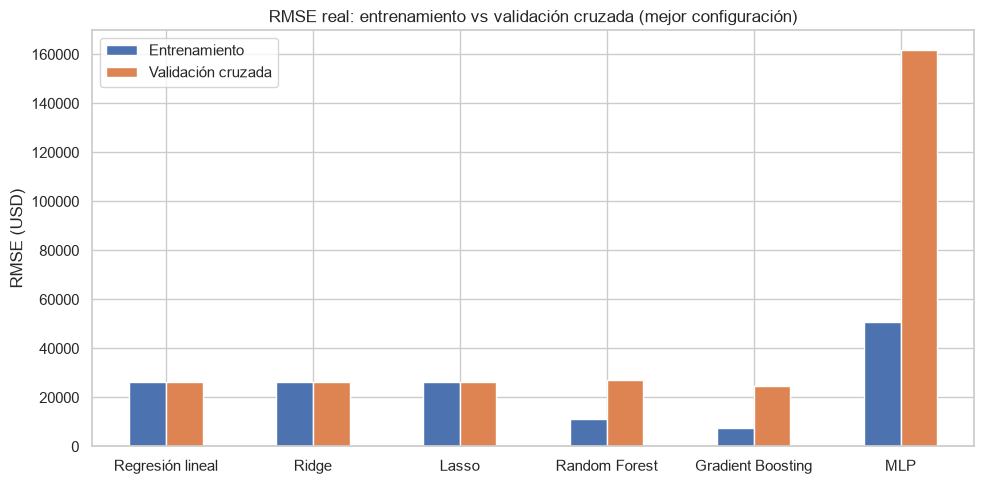

,rmse_train_cv,rmse_test_cv,std_test_cv,brecha_%
Gradient Boosting,7575.5,24689.3,5074.6,225.9
Lasso,26126.9,26237.2,6840.3,0.4
Ridge,26117.2,26346.1,6828.0,0.9
Regresión lineal,26114.9,26367.3,6826.2,1.0
Random Forest,11006.0,27267.9,5558.9,147.8
MLP,50603.2,161640.4,95004.6,219.4


In [8]:
# Brecha entre RMSE de entrenamiento y de validación cruzada
sobreajuste = pd.DataFrame({
    name: {
        "rmse_train_cv": -s.cv_results_["mean_train_score"][s.best_index_],
        "rmse_test_cv": -s.cv_results_["mean_test_score"][s.best_index_],
        "std_test_cv": s.cv_results_["std_test_score"][s.best_index_],
    }
    for name, s in busquedas.items()
}).T
sobreajuste["brecha_%"] = 100 * (sobreajuste["rmse_test_cv"] / sobreajuste["rmse_train_cv"] - 1)

ax = sobreajuste[["rmse_train_cv", "rmse_test_cv"]].plot.bar(figsize=(10, 5), rot=0)
ax.set_title("RMSE real: entrenamiento vs validación cruzada (mejor configuración)")
ax.set_ylabel("RMSE (USD)")
ax.legend(["Entrenamiento", "Validación cruzada"])
plt.tight_layout()
plt.show()

sobreajuste.round(1).sort_values("rmse_test_cv")

## 9. Torneo en el split de validación

Evaluación del mejor estimador de cada modelo sobre `X_val`, que no participó en el ajuste ni en la optimización. Los modelos se ordenan por RMSE real.

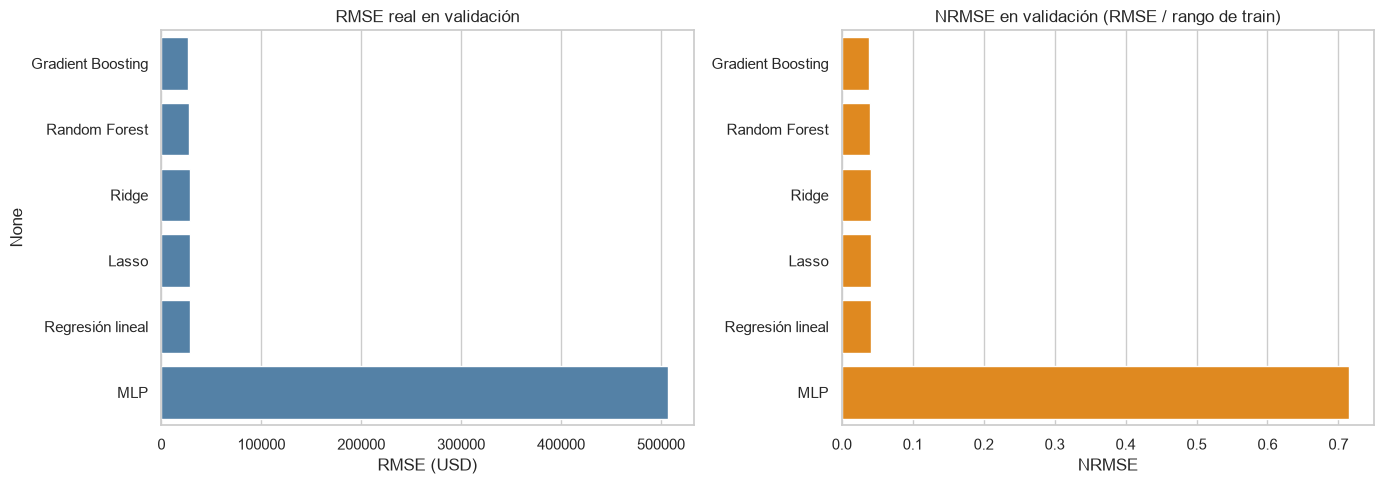

,rmse_real_val,nrmse_val,rmse_cv,brecha_%
Gradient Boosting,"27,015",0.0380,"24,689",225.9
Random Forest,"27,875",0.0393,"27,268",147.8
Ridge,"28,925",0.0407,"26,346",0.9
Lasso,"28,959",0.0408,"26,237",0.4
Regresión lineal,"29,057",0.0409,"26,367",1.0
MLP,"507,287",0.7144,"161,640",219.4


In [9]:
# Métricas en validación
predicciones_val = {name: s.best_estimator_.predict(X_val) for name, s in busquedas.items()}

torneo = pd.DataFrame({
    name: {
        "rmse_real_val": rmse_real(y_val, pred),
        "nrmse_val": nrmse(y_val, pred),
        "rmse_cv": sobreajuste.loc[name, "rmse_test_cv"],
        "brecha_%": sobreajuste.loc[name, "brecha_%"],
    }
    for name, pred in predicciones_val.items()
}).T.sort_values("rmse_real_val")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=torneo["rmse_real_val"], y=torneo.index, ax=axes[0], color="steelblue")
axes[0].set_title("RMSE real en validación")
axes[0].set_xlabel("RMSE (USD)")
sns.barplot(x=torneo["nrmse_val"], y=torneo.index, ax=axes[1], color="darkorange")
axes[1].set_title("NRMSE en validación (RMSE / rango de train)")
axes[1].set_xlabel("NRMSE")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

torneo.style.format({"rmse_real_val": "{:,.0f}", "nrmse_val": "{:.4f}", "rmse_cv": "{:,.0f}", "brecha_%": "{:.1f}"})

## 10. Gráficas de desempeño por modelo

Para cada modelo, en escala real sobre el split de validación:

- **Real vs predicho:** los puntos deben ubicarse sobre la diagonal; desviaciones sistemáticas indican sesgo en ciertos rangos de precio.
- **Residuos vs predicho:** los residuos deben distribuirse alrededor de cero sin patrones; la forma de abanico indica que el error crece con el precio.

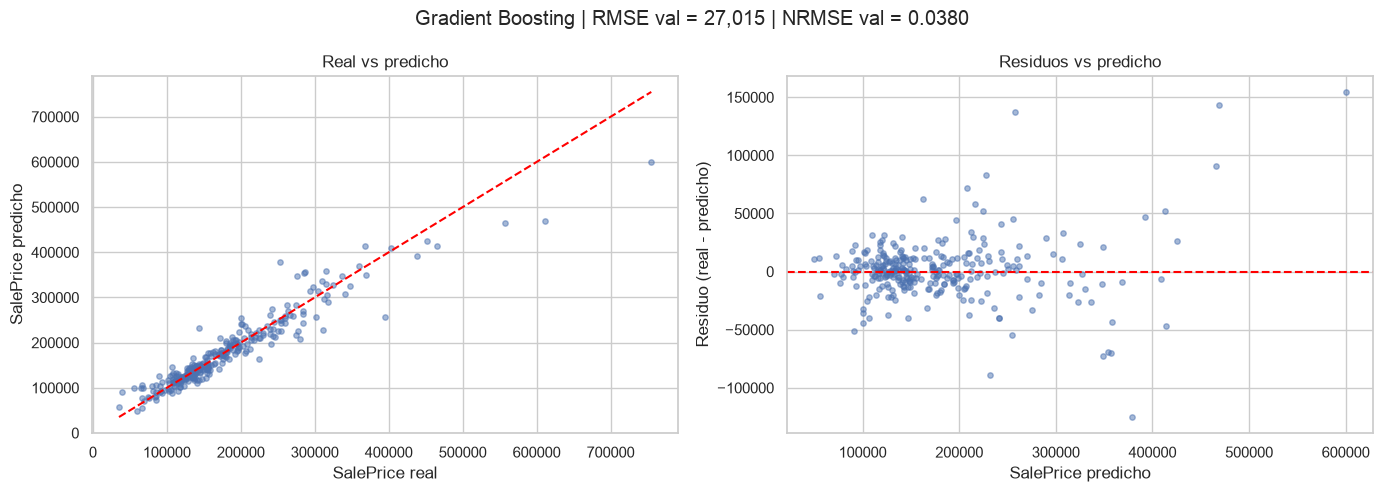

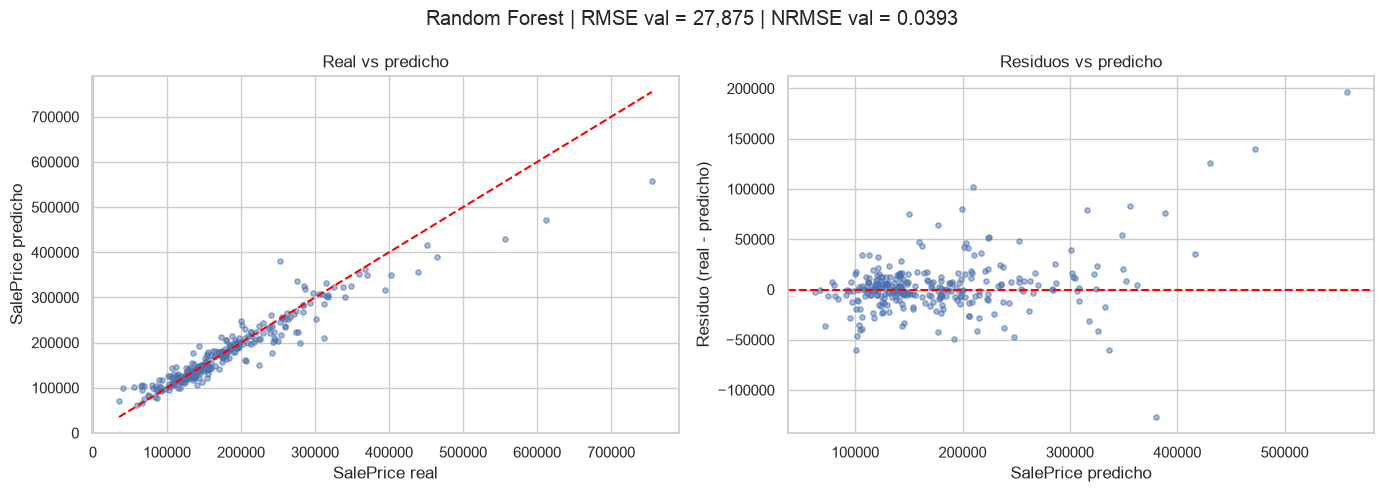

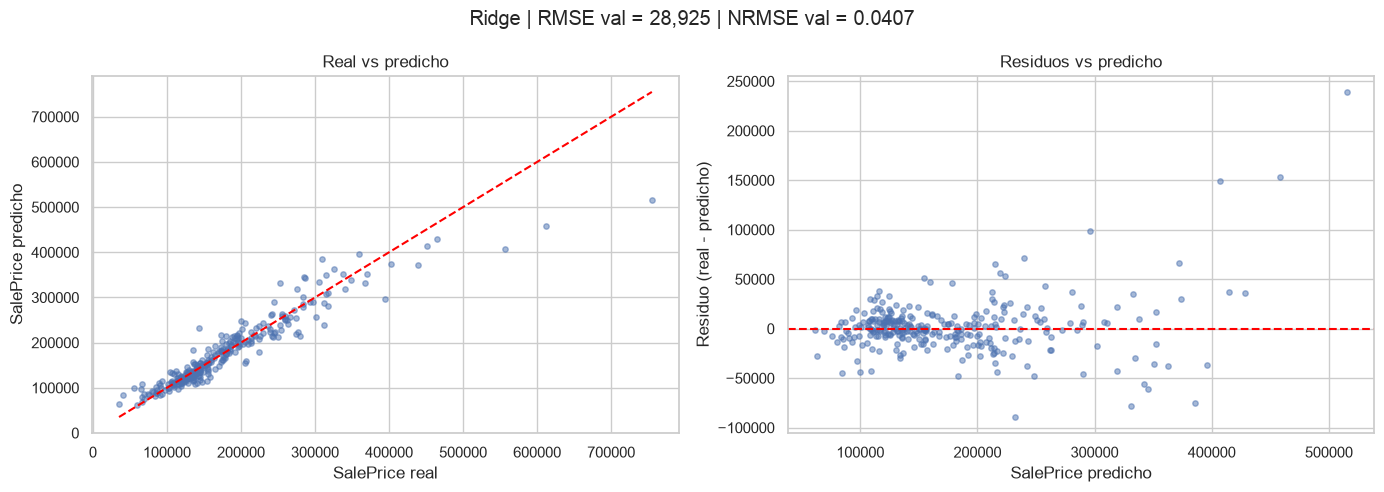

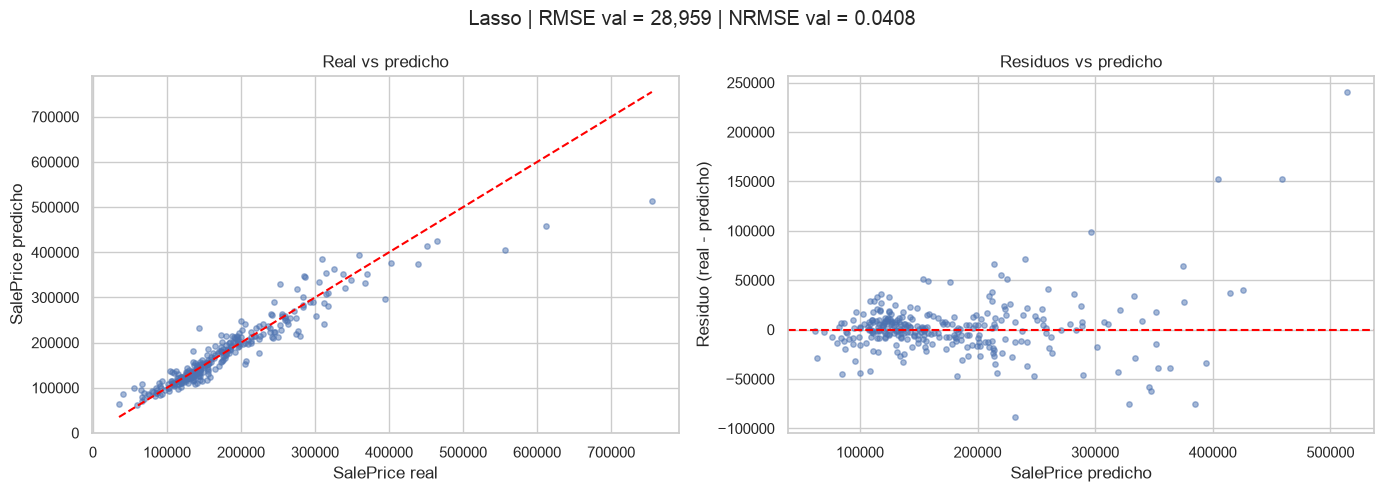

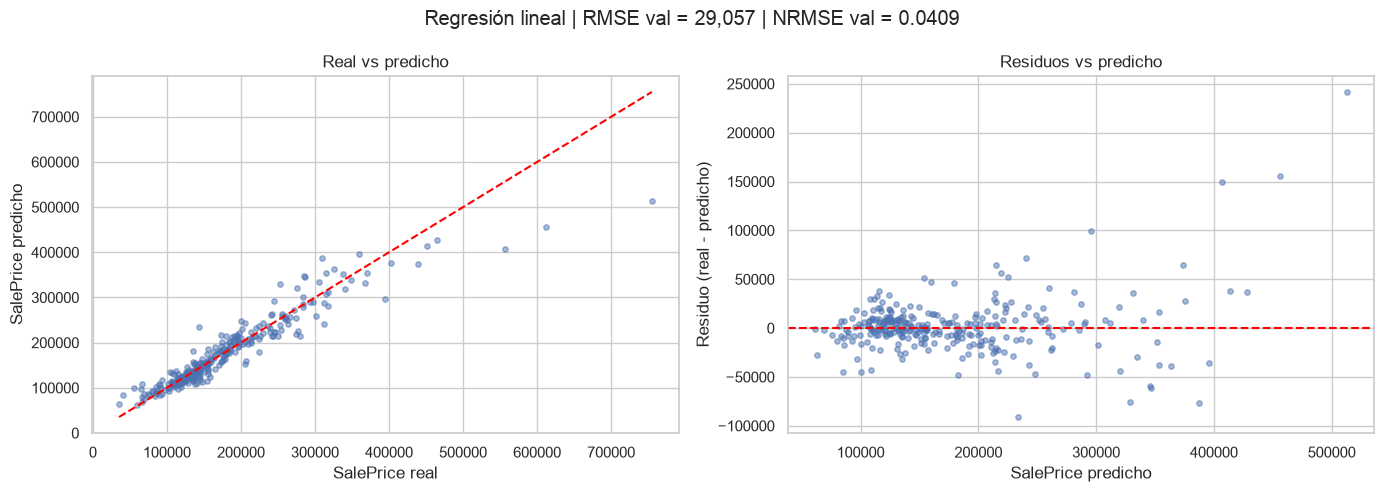

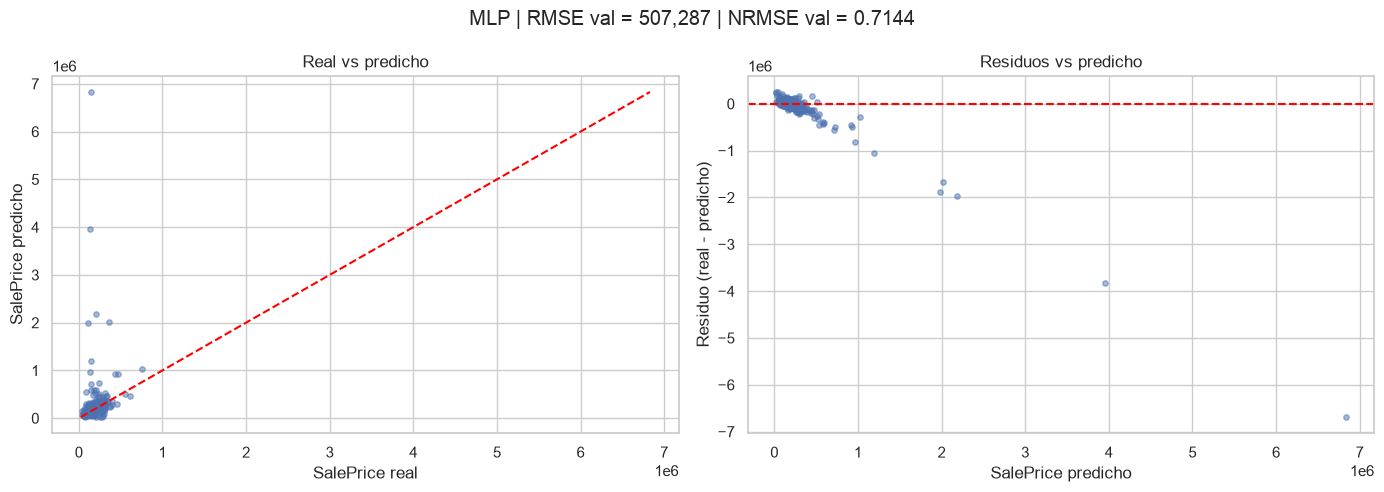

In [12]:
# Real vs predicho y residuos por modelo (escala real)
y_val_real = np.expm1(y_val)

for name in torneo.index:
    pred_real = np.expm1(predicciones_val[name])
    residuos = y_val_real - pred_real

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(
        f"{name} | RMSE val = {torneo.loc[name, 'rmse_real_val']:,.0f} | "
        f"NRMSE val = {torneo.loc[name, 'nrmse_val']:.4f}"
    )

    limites = [min(y_val_real.min(), pred_real.min()), max(y_val_real.max(), pred_real.max())]
    axes[0].scatter(y_val_real, pred_real, alpha=0.5, s=15)
    axes[0].plot(limites, limites, color="red", linestyle="--")
    axes[0].set_title("Real vs predicho")
    axes[0].set_xlabel("SalePrice real")
    axes[0].set_ylabel("SalePrice predicho")

    axes[1].scatter(pred_real, residuos, alpha=0.5, s=15)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_title("Residuos vs predicho")
    axes[1].set_xlabel("SalePrice predicho")
    axes[1].set_ylabel("Residuo (real - predicho)")

    plt.tight_layout()
    plt.show()

## 11. Guardado del modelo ganador

Almacenamiento del modelo con menor RMSE real en validación. Se guarda el `best_estimator_` de su búsqueda: el pipeline completo de ingeniería de características más el modelo, entrenado con `X_train` y la mejor configuración de hiperparámetros. El modelo recibe las columnas de `MODEL_FEATURES` en crudo y predice `SalePrice` en escala log.

In [15]:
# Guardado del modelo ganador (preprocesamiento + modelo)
MODELO_GANADOR_PATH = MODELS_DIR / "modelo_ganador.joblib"

modelo_ganador_nombre = torneo.index[0]
modelo_ganador = busquedas[modelo_ganador_nombre].best_estimator_
joblib.dump(modelo_ganador, MODELO_GANADOR_PATH)

print(f"Modelo ganador: {modelo_ganador_nombre}")
print(f"Hiperparámetros: {busquedas[modelo_ganador_nombre].best_params_}")
print(f"RMSE real val: {torneo.loc[modelo_ganador_nombre, 'rmse_real_val']:,.0f} | NRMSE val: {torneo.loc[modelo_ganador_nombre, 'nrmse_val']:.4f}")
print(f"Guardado en {MODELO_GANADOR_PATH}")
modelo_ganador

PicklingError: Can't pickle <class '__main__.SkewedYeoJohnsonTransformer'>: it's not the same object as __main__.SkewedYeoJohnsonTransformer